# Gridworld


In Reinforcement Learning (RL), a GridWorld is the "Hello World" of environments. It is a discrete, two-dimensional space where an agent moves from cell to cell to maximize its rewards.

It serves as the perfect bridge between theory and practice because every component of a Markov Decision Process (MDP) is visible and countable.

A GridWorld is defined by four core mathematical components:

- States (S): Each cell in the grid (e.g., (x,y) or a flattened index from 0 to 15).

- Actions (A): Usually four discrete moves: Up, Down, Left, and Right.

- Transitions (P): The rules of movement. In a simple grid, this is deterministic (moving 'Right' always lands you in the cell to the right). If you hit a wall, you stay put.

- Rewards (R): The feedback signal.

- Step Penalty: Usually −1 per move to force the agent to find the shortest path.

- Goal: A large positive reward or 0 (with penalties elsewhere).

- Traps: Large negative rewards (e.g., −10) that may end the episode.

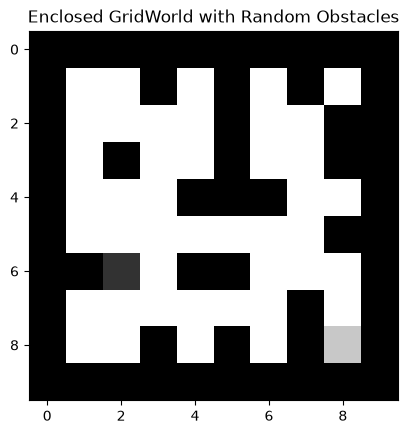

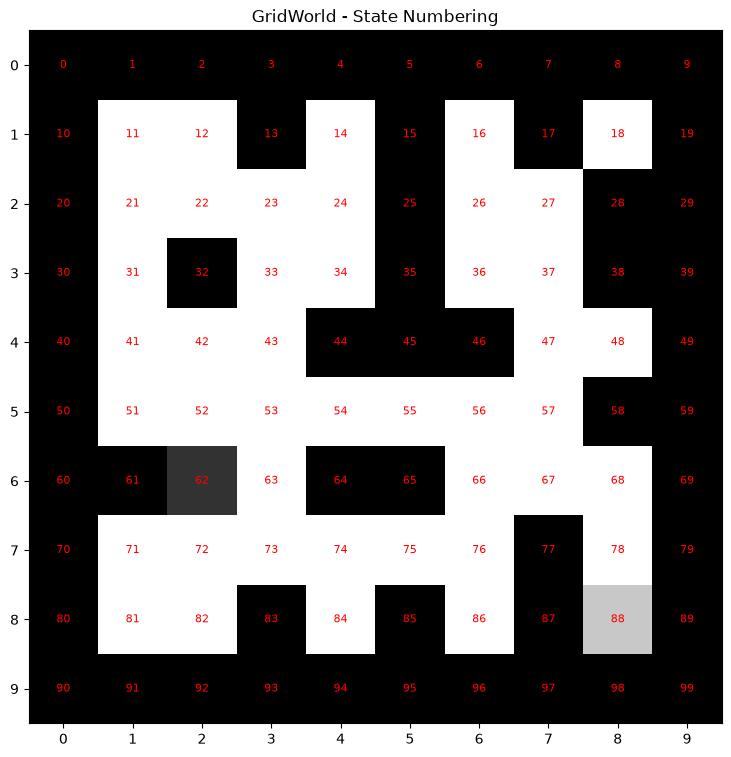

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

# clean 255
# goal 200


def generate_enclosed_map(rows=30, cols=30, wall_density=0.25, trap_density=0.02):
    # Start with a clean white path (255)
    grid = np.full((rows, cols), 255, dtype=np.uint8)
    
    grid[0, :] = 0   # Top wall
    grid[-1, :] = 0  # Bottom wall
    grid[:, 0] = 0   # Left wall
    grid[:, -1] = 0  # Right wall
    
    interior_shape = (rows-2, cols-2)
    random_roll = np.random.rand(*interior_shape)
    
    interior_mask = np.full((rows, cols), False)
    interior_mask[1:-1, 1:-1] = True
    
    grid[(interior_mask) & (np.pad(random_roll < wall_density, 1, constant_values=False))] = 0
    grid[(interior_mask) & (np.pad(random_roll > 1 - trap_density, 1, constant_values=False))] = 50
    
    grid[-2, -2] = 200    # Bottom-right goal
    
    return grid

rows, cols = 10, 10
grid_bitmap = generate_enclosed_map(rows, cols)
plt.imshow(grid_bitmap, cmap='gray')
plt.title("Enclosed GridWorld with Random Obstacles")

plt.figure(figsize=(9, 9))
plt.imshow(grid_bitmap, cmap='gray', vmin=0, vmax=255)

rows, cols = grid_bitmap.shape

for r in range(rows):
    for c in range(cols):
        state = r * cols + c

        plt.text(
            c, r, str(state),
            ha='center',
            va='center',
            color='red',
            fontsize=8
        )

plt.title("GridWorld - State Numbering")
plt.xticks(range(cols))
plt.yticks(range(rows))


plt.show()

In [23]:
# define rewards
WORLD_CONFIG = {
    0:   {"reward": 0,      "terminal": False, "label": "Wall"},   # Penalty handled by 'stay-put'
    50:  {"reward": -10,    "terminal": True,  "label": "Trap"},   # Big penalty, ends game
    200: {"reward": 10,     "terminal": True,  "label": "Goal"},   # Big prize, ends game
    255: {"reward": -1,     "terminal": False, "label": "Path"}    # Step cost to encourage speed
}

# convert config to two maps like the one we generated 
def parse_grid(grid_bitmap):
    rows, cols = grid_bitmap.shape
    reward_grid = np.zeros((rows, cols))
    terminal_mask = np.zeros((rows, cols), dtype=bool)

    for val, props in WORLD_CONFIG.items():
        # Masking: find all coordinates where the bitmap matches the value
        mask = (grid_bitmap == val)
        reward_grid[mask] = props["reward"]
        terminal_mask[mask] = props["terminal"]
        
    return reward_grid, terminal_mask

reward_grid, terminal_mask = parse_grid(grid_bitmap)

## Monte Carlo Gridworld

Monte Carlo Policy Evaluation is a model-free method used to estimate the value function of each state by generating multiple simulated episodes and averaging the returns obtained.

1. Start an episode from the selected state.
2. Follow the given policy to select actions and simulate the agent's movements.
3. Collect the sequence of visited states and rewards until a terminal state is reached or the maximum number of steps is exceeded.
4. Calculate the discounted return for each visited state, considering the rewards obtained from that point until the end of the episode.
5. Repeat this process for a specified number of episodes (`num_episodes`).
6. Estimate the value of each state by averaging the returns collected across the simulated episodes.

The estimated state value is:

$$
V^\pi(s)\approx\frac{1}{N}\sum_{i=1}^{N}G_i(s)
$$

where \(N\) is the number of returns collected for state \(s\), and \(G_i(s)\) is the discounted return observed after visiting that state during episode \(i\).

### First-Visit and Every-Visit Monte Carlo

Monte Carlo Policy Evaluation can be implemented using two different approaches, depending on how repeated visits to the same state within an episode are handled.

**First-Visit Monte Carlo** considers only the first occurrence of each state within an episode. If the agent visits the same state multiple times during an episode, only the return associated with its first visit is used to update the value estimate. Subsequent visits to that state within the same episode are ignored.

**Every-Visit Monte Carlo**, instead, considers every occurrence of a state within an episode. Each visit generates a return, and all these returns are included in the average used to estimate the state's value.

Both approaches estimate the same state-value function, but differ in how the returns are collected and averaged.

Unlike the analytical Bellman approach, Monte Carlo does not require solving a system of linear equations or explicitly computing the transition matrix. Instead, it estimates state values through repeated simulations and statistical averaging.

This makes Monte Carlo particularly useful when the environment's transition probabilities are unknown or when the value function is easier to estimate through simulated experience than through an analytical model.

In [24]:
MOVEMENTS = [(-1, 0), (1, 0), (0, -1), (0,1)]
#               UP -- DOWN -- LEFT -- RIGHT  

def step(s, action_idx, grid_bitmap, reward_grid, terminal_mask):
    #conert the index s to a row, col position and retrieve rewards

    rows, cols = grid_bitmap.shape
    row, col = divmod(s, cols)
    
    # Define movement offsets
    dr, dc = MOVEMENTS[action_idx]
    new_row, new_col = row + dr, col + dc
    
    # Check for Wall or Boundary
    # If out of bounds or hitting a wall (VAL_WALL = 0), stay in current state
    if not (0 <= new_row < rows and 0 <= new_col < cols) or grid_bitmap[new_row, new_col] == 0:
        s_next = s
    else:
        s_next = new_row * cols + new_col
    
    # Get reward from the landing cell
    land_r, land_c = divmod(s_next, cols)
    reward = reward_grid[land_r, land_c]
    done = terminal_mask[land_r, land_c]
    
    return s_next, reward, done

def simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, gamma=0.9, max_steps=100):
    state = start_state
    episode_history = []
    
    for t in range(max_steps):
        action = policy(state)
        #print(f"Step {t}: State {state}, Action {action}")
        next_state, reward, done = step(state, action, grid_bitmap, reward_grid, terminal_mask)
        
        episode_history.append((state, action, next_state, reward))
        
        if done:
            break
        state = next_state
        
    # Calculate Return G_t = sum of discounted rewards
    G = 0
    # We calculate backwards for efficiency: G = r + gamma * G
    transitions = []
    returns = []
    for state, action, next_state, r in reversed(episode_history):
        G = r + gamma * G
        returns.append(G)
        transitions.append((state, action, next_state, G))
    
    # Return starting state and the total discounted return from t=0
    return returns[-1], transitions

In [25]:
def random_policy(s):  # Random policy for testing
    return np.random.randint(0, 4)

In [26]:
G_final, episode_history = simulate_episode(12, grid_bitmap, reward_grid, terminal_mask, random_policy, gamma=0.9, max_steps=100)

**TIP: Use the Incremental Mean**

Instead of storing all the returns and recomputing their average after every episode, we can use the **incremental mean** to update the state-value estimate online.

The update rule is:

$$
V_{n+1}(s)=V_n(s)+\frac{1}{N(s)}\left(G-V_n(s)\right)
$$

where:
- $V_n(s)$ is the current estimated value of state \(s\).
- $G$ is the newly observed return.
- $N(s)$ is the number of times state \(s\) has been visited and considered for the update.

This approach avoids storing all previously collected returns, reducing memory usage while producing the same arithmetic mean.
In our implementation, the `visited_states` set ensures that each state is updated only once per episode, corresponding to the **First-Visit Monte Carlo** approach.

In [27]:
def first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100):
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # To count first visits

    for _ in range(num_episodes):
        last_return, episode_history = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)
        visited_states = set()
        
        for state, action, next_state, G in episode_history:
            if state not in visited_states:
                visited_states.add(state)
                returns_count[state] += 1
                V_mc[state] += (G - V_mc[state]) / returns_count[state]  # Incremental mean update

    return V_mc.reshape(rows, cols)

In [28]:
def every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100):
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # To count visits

    for _ in range(num_episodes):
        last_return, episode_history = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)
        
        for state, action, next_state, G in episode_history:
            returns_count[state] += 1
            V_mc[state] += (G - V_mc[state]) / returns_count[state]  # Incremental mean update

    return V_mc.reshape(rows, cols)

In [29]:
start_state = 12 
#V_mc_grid = monte_carlo_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=500)
V_mc_grid_fv = first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=10000, max_steps=200)
V_mc_grid_ev = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=10000, max_steps=200)

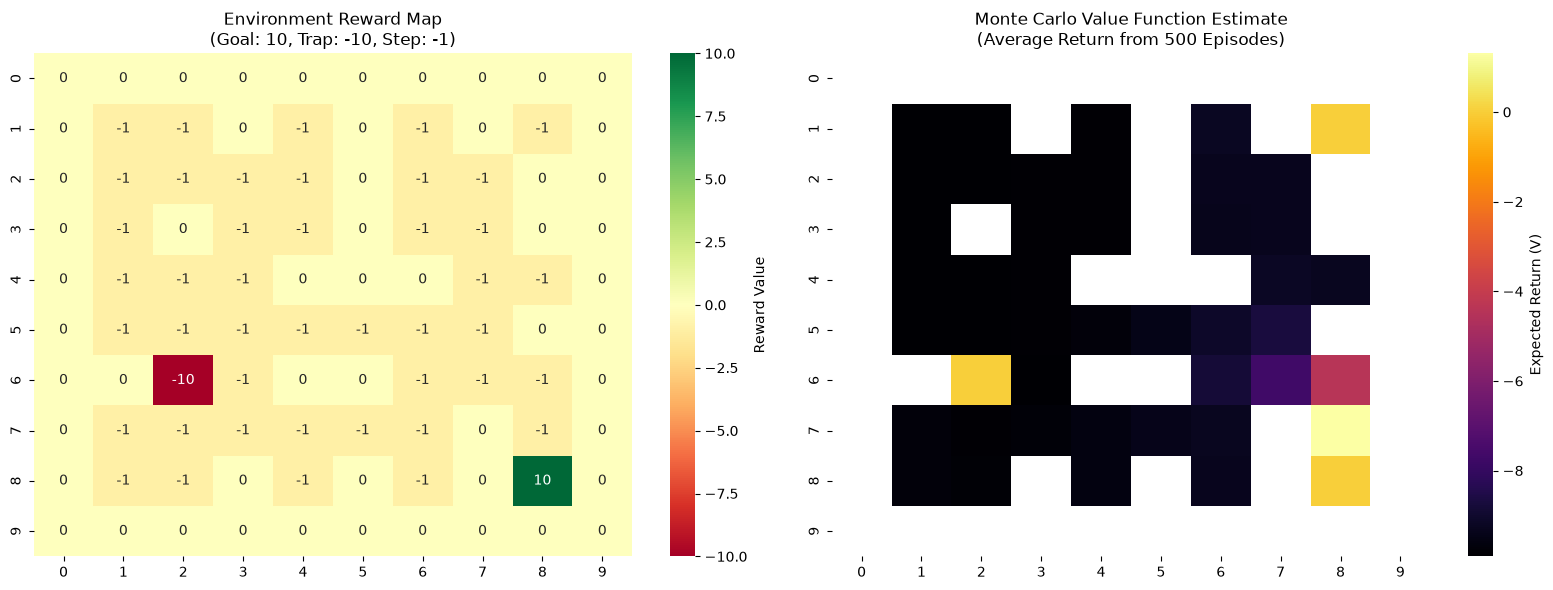

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(reward_grid, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Reward Value'})
ax[0].set_title("Environment Reward Map\n(Goal: 10, Trap: -10, Step: -1)")

# We mask the walls so they appear empty (Value is irrelevant there)
mask_walls = (grid_bitmap == 0)
sns.heatmap(V_mc_grid_ev, annot=False, cmap="inferno", ax=ax[1], mask=mask_walls, cbar_kws={'label': 'Expected Return (V)'})
ax[1].set_title("Monte Carlo Value Function Estimate\n(Average Return from 500 Episodes)")

plt.tight_layout()
plt.show()

## Solving the problem with the bellman equations

This is the "mathematical engine" of the lab. Since we are using a Fixed Random Policy, the Bellman Equation transitions from a complex optimization problem to a straightforward system of linear equations.1. The Bellman Expectation EquationFor a fixed policy $\pi$, the value of a state $s$ is the expected sum of future discounted rewards. Mathematically, it is expressed as:$$V^{\pi}(s) = \sum_{a \in A} \pi(a|s) \sum_{s' \in S, r \in R} p(s', r|s, a) \left[ r + \gamma V^{\pi}(s') \right]$$


We are using a Uniform Random Policy ($\pi(a|s) = 0.25$) and the environment is Deterministic ($p=1$ for the result of an action), the equation simplifies to:$$V(s) = 0.25 \sum_{a \in \{U,D,L,R\}} \left( \text{Reward}(s, a) + \gamma V(s_{next}) \right)$$ 


To solve this for all $N$ states simultaneously, we rewrite it in matrix-vector form. This turns $16$ (or $100$) individual equations into one single operation:$$\mathbf{V} = \mathbf{R} + \gamma \mathbf{P} \mathbf{V}$$


Where:

- $\mathbf{V}$: An $N \times 1$ vector of values we want to find.

- $\mathbf{R}$: An $N \times 1$ vector of expected rewards for each state under the random policy.

- $\mathbf{P}$: An $N \times N$ Transition Probability Matrix, where $P_{ij}$ is the probability of landing in state $j$ starting from state $i$.

- $\gamma$: The discount factor (e.g., $0.9$). 

P encodes our policy, in this case it is a matrix which has entries 0 for each element unreachable and 0.25 for each element reachable! Second note we can factor out an "expected reward" since we can loop on all the states from there and factor out this R vector (which results from the multipltication $PR^*$ where $R^*$ contains all the rewards)

To find $\mathbf{V}$, we rearrange the equation using linear algebra:Move the $V$ terms to one side: $$ \mathbf{V} - \gamma \mathbf{P} \mathbf{V} = \mathbf{R}$$ Factor out $\mathbf{V}$: $$(\mathbf{I} - \gamma \mathbf{P}) \mathbf{V} = \mathbf{R}$$ Solve for $\mathbf{V}$: $$\mathbf{V} = (\mathbf{I} - \gamma \mathbf{P})^{-1} \mathbf{R} $$ 



### The Transition Matrix P and the Expected Reward Vector R

The transition matrix **P** encodes both the environment dynamics and our fixed random policy.

Since we use a Uniform Random Policy, each action has a probability of 0.25. Therefore, each element \(P_{ij}\) represents the probability of transitioning from state \(i\) to state \(j\), taking into account all possible actions:

$$
P_{ij}=\sum_a \pi(a|s_i)P(s_j|s_i,a)
$$

Since the environment is deterministic, each action leads to exactly one next state. Consequently, \(P_{ij}\) is 0.25 for every action leading to state \(j\), and 0 if no action leads to that state. If multiple actions lead to the same state (for example, when the agent hits a wall), their probabilities are added.

The expected reward vector **R** contains the average immediate reward obtained from each state under our policy:

$$
R_i=\sum_a\pi(a|s_i)Reward(s_i,a)
$$

Thus, we can compute the expected reward for every state by averaging the rewards associated with its four possible actions.

Finally, the Bellman equation becomes:

$$
\mathbf V=\mathbf R+\gamma\mathbf P\mathbf V
$$

and can be solved directly using linear algebra:

$$
\boxed{\mathbf V=(\mathbf I-\gamma\mathbf P)^{-1}\mathbf R}
$$

In [31]:
def build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask, gamma=0.9):
    rows, cols = grid_bitmap.shape
    num_states = rows * cols

    # Initialize P as an N x N matrix and R as an N x 1 vector
    P = np.zeros((num_states, num_states))
    R_vec = np.zeros(num_states)

    for s in range(num_states):
        r, c = divmod(s, cols)
        
        # In an MDP, terminal states transition to themselves with prob 1.0
        if terminal_mask[r, c] or grid_bitmap[r, c] == 0: # it is a wall or terminal state
            P[s, s] = 1.0
            continue
            
        prob_per_action = 0.25
        for a_idx in range(4):
            # Use our step logic to find where this action leads
            # dr, dc = [(-1,0), (1,0), (0,-1), (0,1)][a_idx]
            s_next, reward, _ = step(s, a_idx, grid_bitmap, reward_grid, terminal_mask)
            
            # Update Transition Matrix: P[from_state, to_state]
            P[s, s_next] += prob_per_action
            
            # Update Reward Vector: R[state] is the expected immediate reward
            # R(s) = sum_{a} pi(a|s) * Reward(s, a)
            R_vec[s] += prob_per_action * reward
            
    return P, R_vec


def solve_bellman_analytical(P, R_vec, gamma=0.9):
    """
    Solves (I - gamma*P)V = R
    """
    num_states = P.shape[0]
    I = np.eye(num_states)
    
    # Solve the linear system Ax = b 
    # where A = (I - gamma*P) and b = R_vec
    A = I - gamma * P
    V_exact = np.linalg.solve(A, R_vec)
    
    return V_exact

In [32]:
P, R_vec = build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask)
V_exact = solve_bellman_analytical(P, R_vec, gamma=0.9)

V_exact_grid = V_exact.reshape(rows, cols)

R_expected_grid = R_vec.reshape(rows, cols)

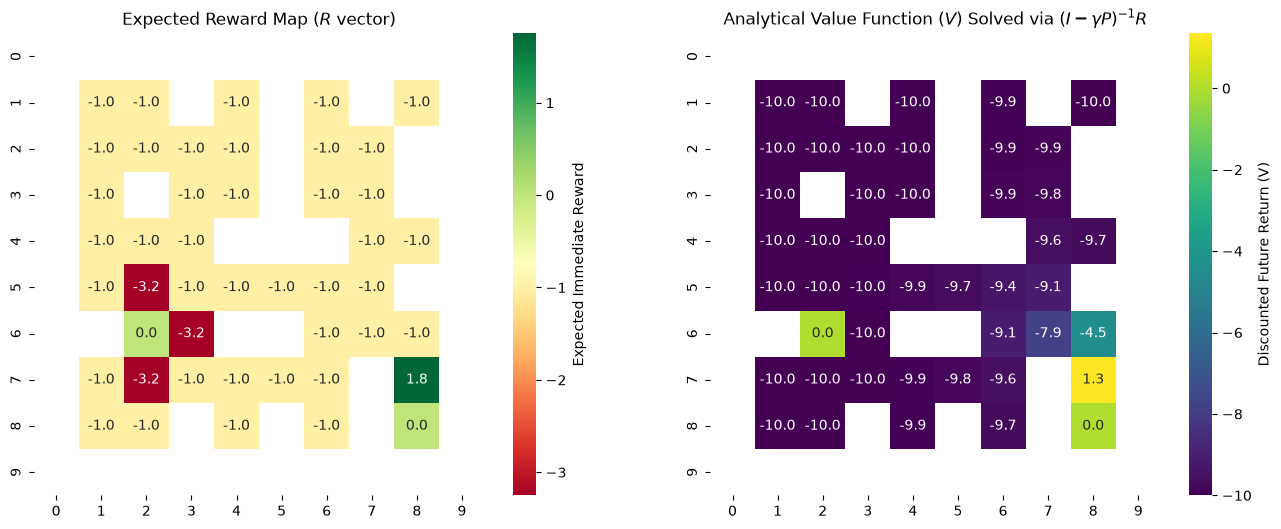

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Define the wall mask
wall_mask = (grid_bitmap == 0)

# --- Plot 1: Expected Rewards (R_vec) ---
sns.heatmap(R_expected_grid, mask=wall_mask, annot=True, fmt=".1f", 
            cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Expected Immediate Reward'})
ax[0].set_title(r"Expected Reward Map ($R$ vector)")

# --- Plot 2: Exact Value Function (V) ---
sns.heatmap(V_exact_grid, mask=wall_mask, annot=True, fmt=".1f",
            cmap="viridis", ax=ax[1], cbar_kws={'label': 'Discounted Future Return (V)'})
ax[1].set_title(r"Analytical Value Function ($V$) Solved via $(I - \gamma P)^{-1} R$")

plt.show()

## Policy extraction

Now from this V we can extract a greedy policy!

For each state we can use as a policy to move towards the state that maximizes reward.

Then redo the montecarlo step and see what happens to the Value function.

In [34]:
def extract_greedy(V, grid_bitmap, terminal_mask):
    nrows = V.shape[0]
    ncols = V.shape[1]

    policy_vals = np.zeros(nrows * ncols, dtype=np.int32) - 1 
    for i in range(nrows):
        for j in range(ncols):
            idx = i*ncols + j

            # not process walls and final state
            if grid_bitmap[i, j] == 0 or terminal_mask[i, j]:
                continue

            # check not a wall not a trap
            up_val = V[i - 1, j] if (grid_bitmap[i - 1, j] != 0 and grid_bitmap[i - 1, j] != 50) else -np.inf

            down_val = V[i + 1, j] if (grid_bitmap[i + 1, j] != 0 and grid_bitmap[i + 1, j] != 50) else -np.inf

            left_val = V[i, j - 1] if (grid_bitmap[i, j - 1] != 0 and grid_bitmap[i, j - 1] != 50) else -np.inf

            right_val = V[i, j + 1] if (grid_bitmap[i, j + 1] != 0 and grid_bitmap[i, j + 1] != 50) else -np.inf

            policy_vals[idx] = np.argmax([up_val, down_val, left_val, right_val])


    return policy_vals
policy_vals = extract_greedy(V_exact.reshape(grid_bitmap.shape), grid_bitmap, terminal_mask) 


    

Now apply this policy to the montecarlo

In [35]:
def greedy_policy(s):
    return policy_vals[s]

V_mc_greedy = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, greedy_policy, num_episodes=500)

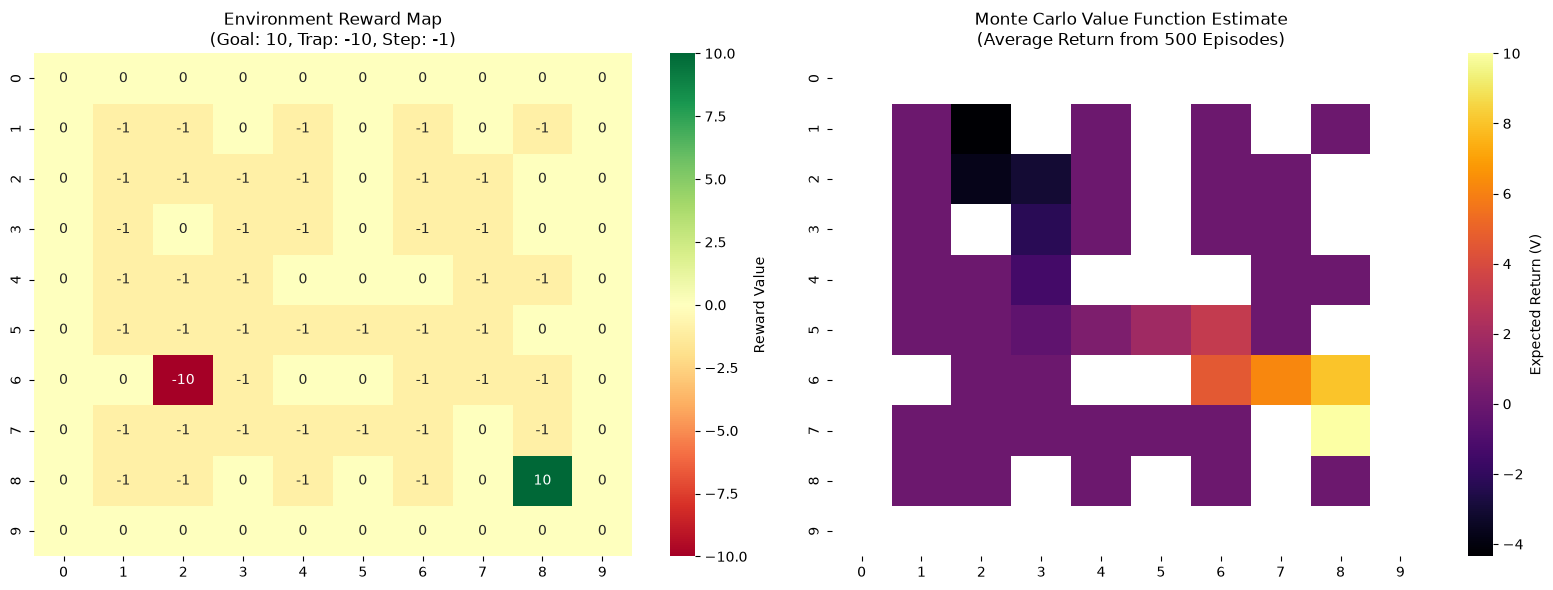

In [36]:
# visualize greedy policy results

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(reward_grid, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Reward Value'})
ax[0].set_title("Environment Reward Map\n(Goal: 10, Trap: -10, Step: -1)")

# We mask the walls so they appear empty (Value is irrelevant there)
mask_walls = (grid_bitmap == 0)
sns.heatmap(V_mc_greedy, annot=False, cmap="inferno", ax=ax[1], mask=mask_walls, cbar_kws={'label': 'Expected Return (V)'})
ax[1].set_title("Monte Carlo Value Function Estimate\n(Average Return from 500 Episodes)")

plt.tight_layout()
plt.show()

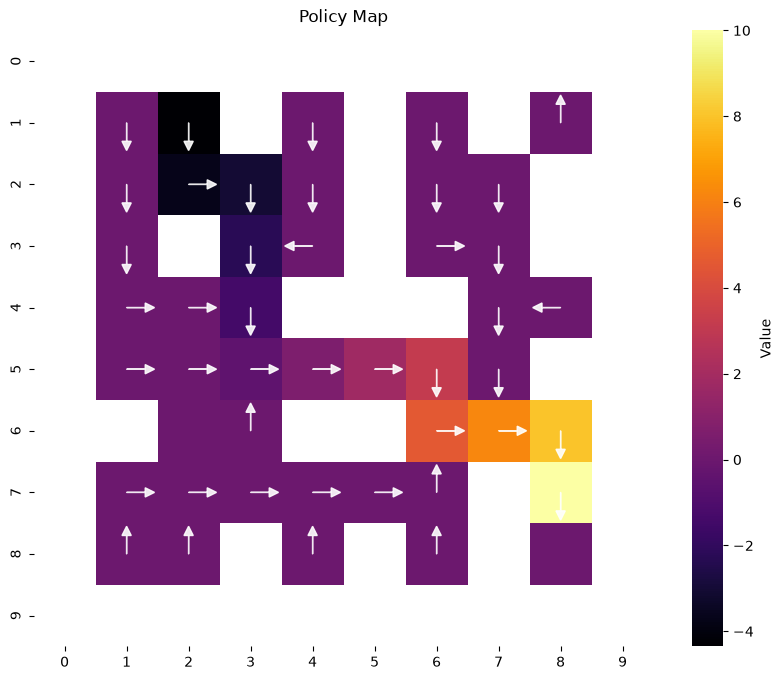

In [37]:
def plot_policy_from_func(V_grid, grid_bitmap, policy_func, title="Policy Map"):
    nrows, ncols = grid_bitmap.shape
    plt.figure(figsize=(10, 8))
    
    # Background Heatmap
    mask_walls = (grid_bitmap == 0)
    sns.heatmap(V_grid, annot=False, cmap='inferno', mask=mask_walls, cbar_kws={'label': 'Value'})
    
    arrows = {0: (0, -0.3), 1: (0, 0.3), 2: (-0.3, 0), 3: (0.3, 0)}
    
    for i in range(nrows):
        for j in range(ncols):
            s = i * ncols + j
            
            # Don't draw arrows on walls or terminal states
            if grid_bitmap[i, j] in [0, 50, 200]:
                continue
                
            # EXECUTE the policy function
            action = policy_func(s)
            
            dx, dy = arrows[action]
            plt.arrow(j + 0.5, i + 0.5, dx, dy, 
                      head_width=0.15, head_length=0.15, 
                      fc='white', ec='white', alpha=0.9)

    plt.title(title)
    plt.show()

plot_policy_from_func(V_mc_greedy, grid_bitmap, greedy_policy)

Note that we can write a simplified form for the Belman equation also in this case since the policy is not random but it is deterministic.

An additional excercise is to retrieve the exact Value function also in this case using the belman equation.

In [38]:
def epsilon_greedy_policy(s, epsilon=0.1):
    if np.random.rand() < epsilon:
        return np.random.randint(0, 4)  # Explore: random action
    else:
        return policy_vals[s]  # Exploit: greedy action

## A sort of policy-iteration

See how the policy improves starting from random

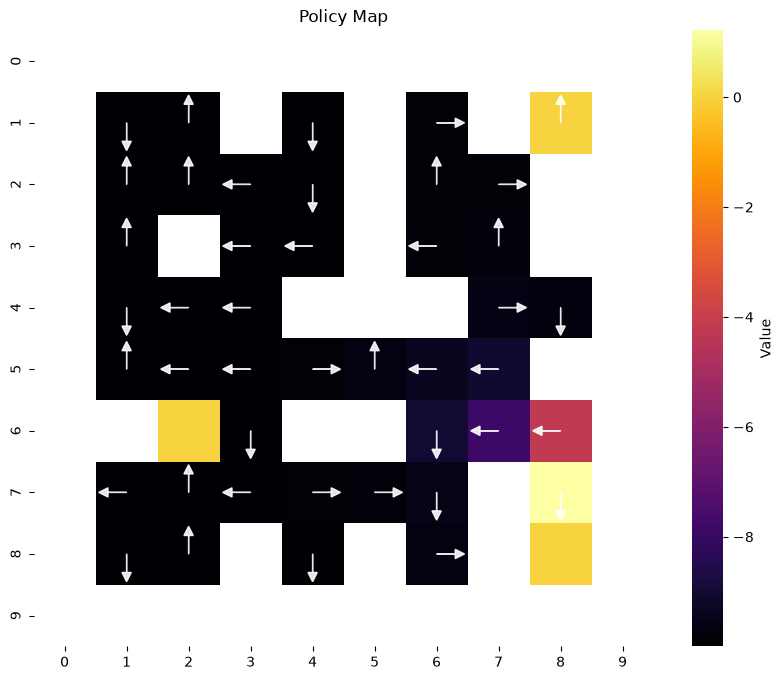

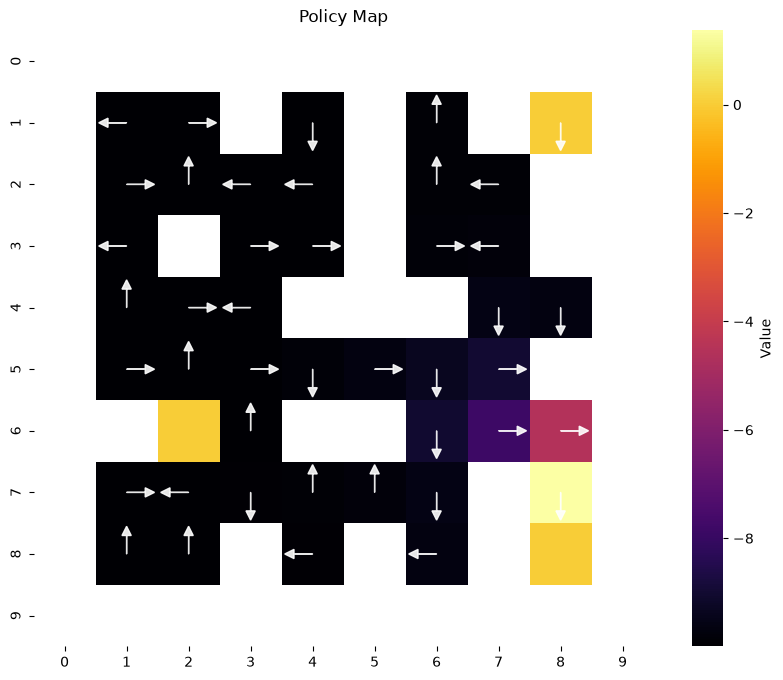

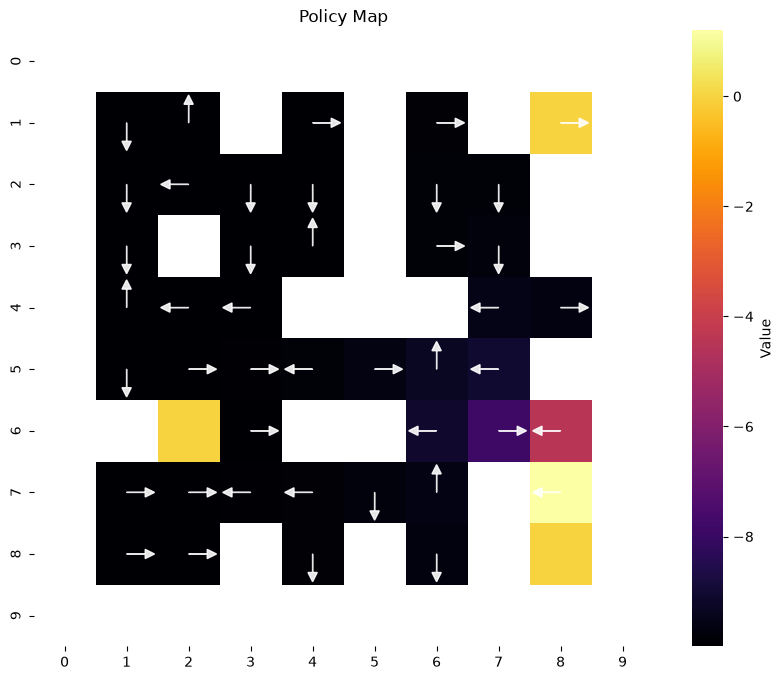

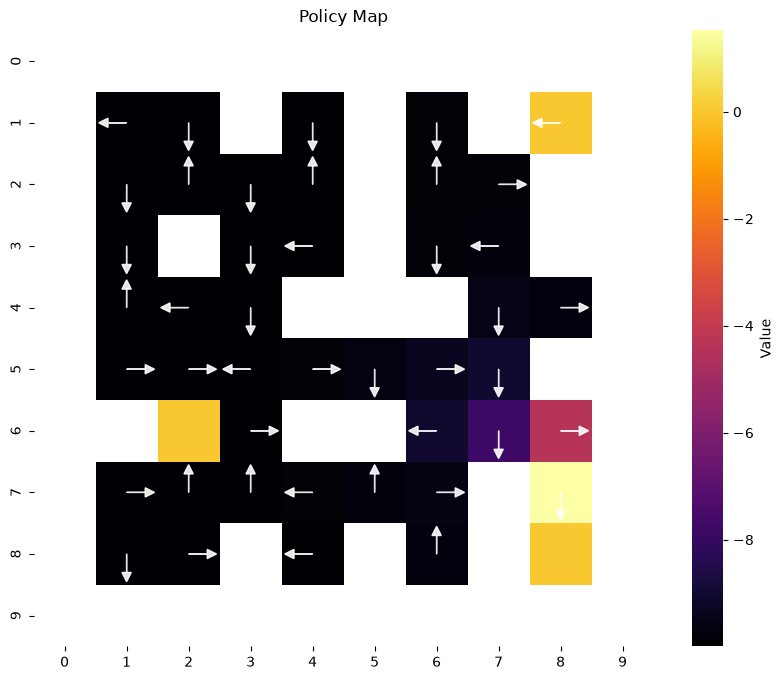

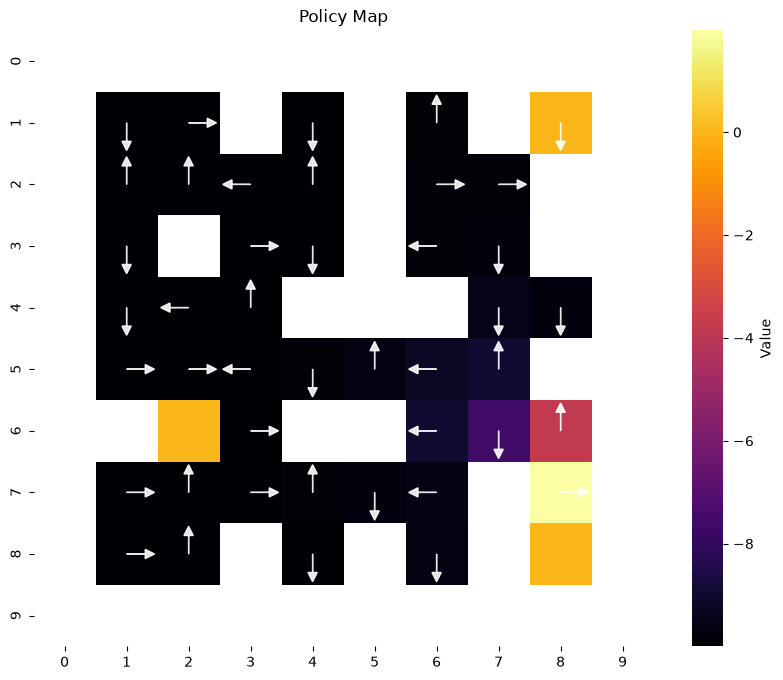

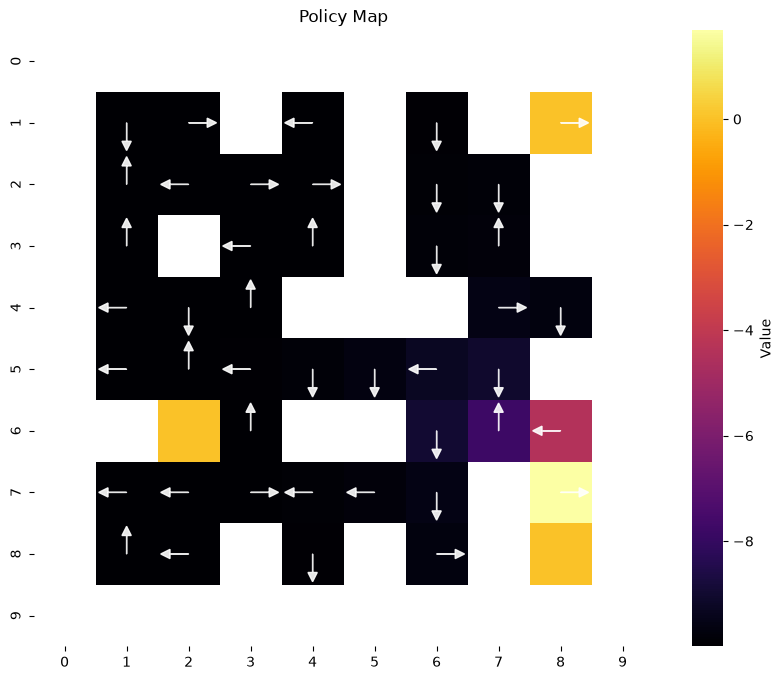

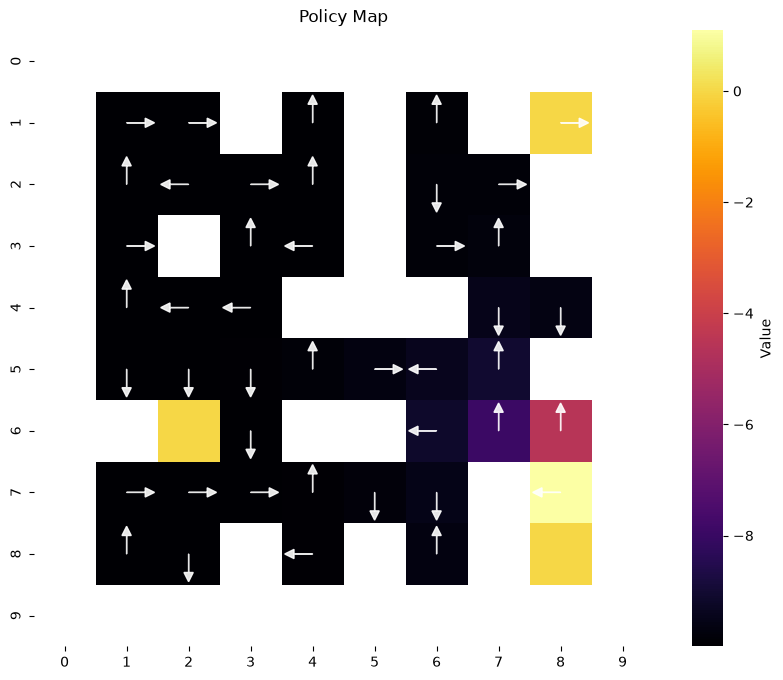

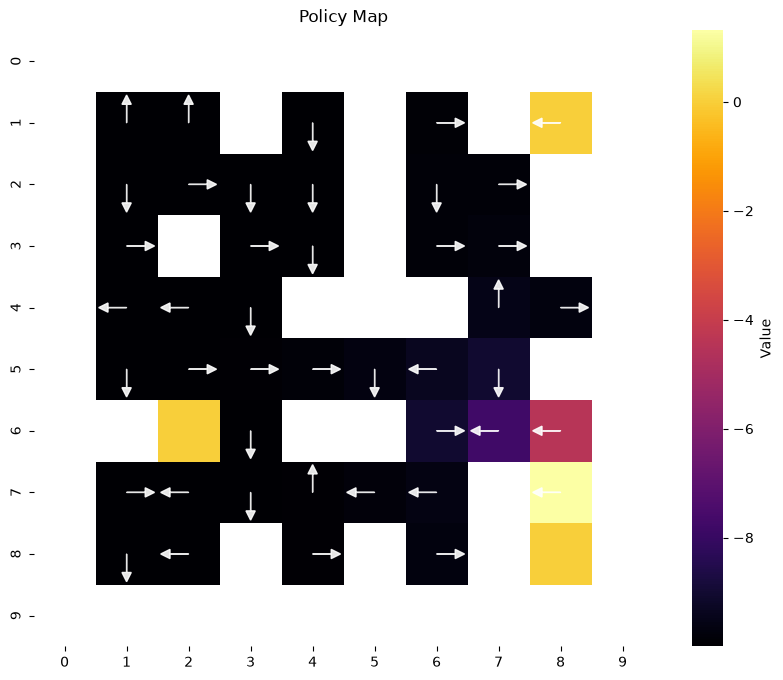

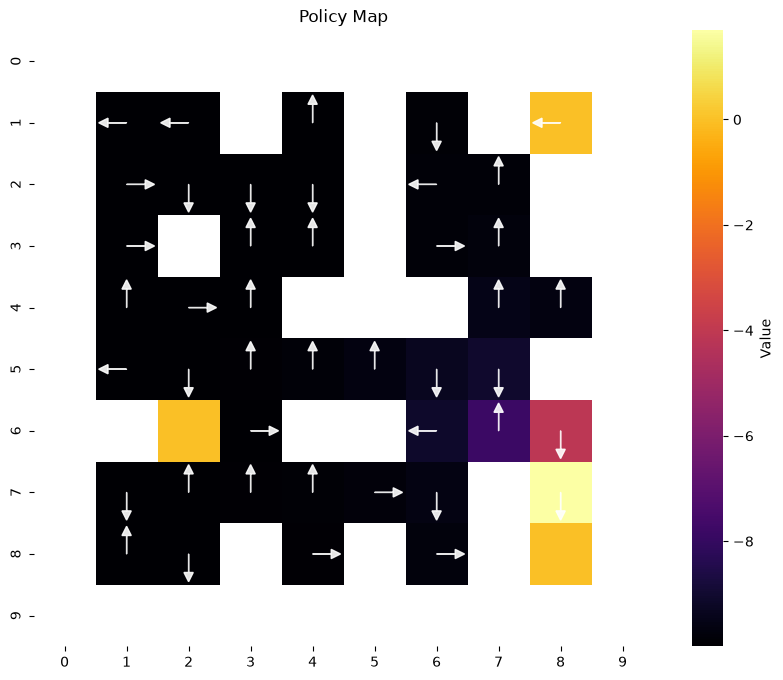

KeyboardInterrupt: 

In [39]:
# extract a starting greedy from 
# lets see if we run multiple times this cell

def greedy_policy_to_improve(s):
    return np.random.randint(0, 4)  # Start with a random policy

for _ in range(20):
    V_mc_grid = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, greedy_policy_to_improve, num_episodes=10000, max_steps=500)

    policy_vals_to_improve = extract_greedy(V_mc_grid, grid_bitmap, terminal_mask) 

    def epsilon_greedy_policy(s, epsilon=0.1):
        if np.random.rand() < epsilon:
            return np.random.randint(0, 4)  # Explore: random action
        else:
            return policy_vals[s]  # Exploit: greedy action

    plot_policy_from_func(V_mc_grid, grid_bitmap, greedy_policy_to_improve)